# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [2]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: <StringArray>
[ 'United States',          'China',          'India',        'Germany',
 'United Kingdom',         'France',         'Brazil',          'Japan',
         'Canada',      'Australia',    'South Korea',         'Russia',
   'South Africa',         'Mexico',      'Indonesia']
Length: 15, dtype: str

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


---
## Task — Multi-Series Line Chart with Highlight

**What to build:** A line chart showing CO2 emissions over time for **all Asian countries** in the dataset, with one country highlighted.

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

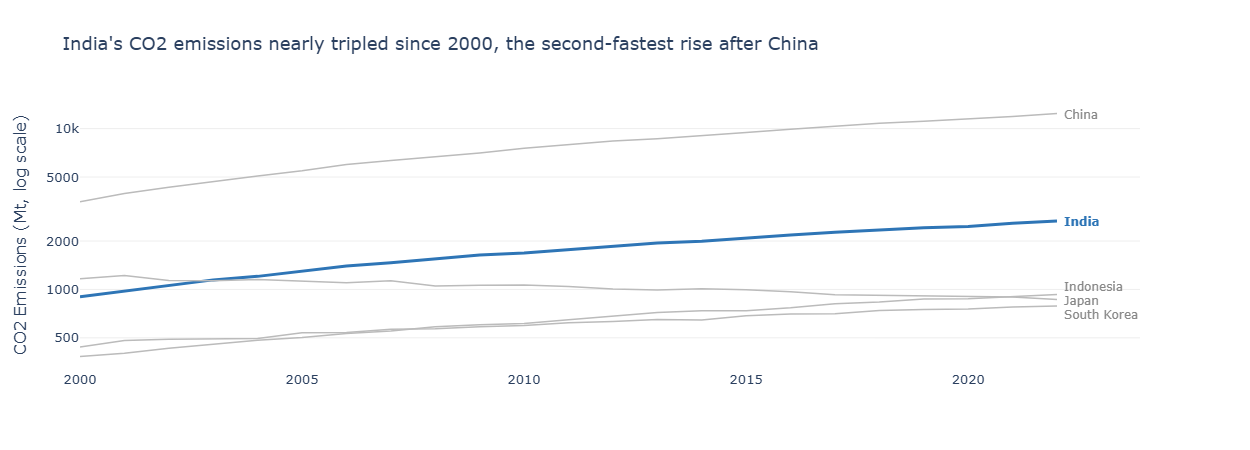

In [5]:
# Task — Multi-series line with highlight
# YOUR CODE HERE

import numpy as np

# Keep only the Asian countries
asia = df.loc[df['Region'] == 'Asia']

# Choose a country to highlight
highlight = 'India'

# Colour map: highlight in colour, everything else grey
color_map = {c: '#2E75B6' if c == highlight else '#EEEEEE' for c in asia['Country'].unique()}

fig = px.line(asia, x='Year', y='CO2_Mt', color='Country',
              color_discrete_map=color_map,
              labels={'CO2_Mt': 'CO2 Emissions (Mt, log scale)', 'Year': ''},
              title="India's CO2 emissions nearly tripled since 2000, the second-fastest rise after China",
              template='plotly_white',
              log_y=True,   # log scale: China is so large it squashes the other lines together
              height=450)

# Thin grey lines for context, no legend (we label directly)
fig.update_traces(line=dict(width=1.5), showlegend=False)

# Thicker line for the highlighted country
fig.update_traces(line=dict(width=3), selector=dict(name=highlight))

# Direct labels at the end of every line (grey for context, blue for highlight)
# small vertical nudges stop the three close labels from overlapping
nudge = {'Indonesia': 8, 'South Korea': -8}
last_year = asia['Year'].max()
for _, row in asia.loc[asia['Year'] == last_year].iterrows():
    is_hl = row['Country'] == highlight
    fig.add_annotation(
        x=last_year, y=np.log10(row['CO2_Mt']),   # log axis: annotation y is in log10 units
        text=row['Country'], showarrow=False,
        xanchor='left', xshift=5, yshift=nudge.get(row['Country'], 0),
        font=dict(color='#2E75B6' if is_hl else '#888888',
                  size=12, weight='bold' if is_hl else 'normal')
    )

fig.update_layout(
    font=dict(size=13),
    xaxis=dict(showgrid=False),
    yaxis=dict(gridcolor='#EEEEEE', tickvals=[500, 1000, 2000, 5000, 10000]),   # a few clean ticks
    margin=dict(r=110)   # room for the labels on the right
)

fig.show()
